# Classification of Respiratory Sounds (ICBHI / Respiratory Sound Database)
**Task:** 4-class respiratory *cycle* classification: Normal, Crackle, Wheeze, Both  
**Pipeline:** audio, respiratory cycles, log-mel spectrogram, CNN, evaluation  
**Imbalance handling:** patient-wise split, class weights, SpecAugment, macro-F1 and ICBHI score


## 1. Setup

In [ ]:
!pip -q install librosa kagglehub

In [ ]:
import os, glob, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import librosa, librosa.display
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import classification_report, confusion_matrix, f1_score, balanced_accuracy_score
from sklearn.utils.class_weight import compute_class_weight
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

# ---------- Config ----------
SR        = 8000          # resample all audio to 8 kHz (lung sounds are mostly < 2 kHz)
DURATION  = 5             # seconds per cycle (pad / crop)
N_SAMPLES = SR * DURATION
N_FFT     = 512
HOP       = 128
N_MELS    = 64
MIN_CYCLE = 0.5           # drop cycles shorter than this (seconds)
BATCH     = 32
EPOCHS    = 60

CLASS_NAMES = ["Normal", "Crackle", "Wheeze", "Both"]
print("TF:", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))

TF: 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Download the dataset
This uses `kagglehub`. If it asks for credentials, create a Kaggle API token (Kaggle > Settings > *Create New Token*), upload `kaggle.json` to Colab, and run the commented alternative below.

In [ ]:
import kagglehub
path = kagglehub.dataset_download("vbookshelf/respiratory-sound-database")
print("Downloaded to:", path)

# --- Alternative (if kagglehub needs login): upload kaggle.json first, then run: ---
# !mkdir -p ~/.kaggle && cp kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
# !kaggle datasets download -d vbookshelf/respiratory-sound-database -p /content/data --unzip
# path = "/content/data"

100%|██████████| 3.69G/3.69G [04:24<00:00, 15.0MB/s]

Extracting files...


Downloaded to: /root/.cache/kagglehub/datasets/vbookshelf/respiratory-sound-database/versions/2


In [ ]:
wavs = glob.glob(os.path.join(path, "**", "audio_and_txt_files", "*.wav"), recursive=True)
AUDIO_DIR = os.path.dirname(wavs[0])
DIAG_CSV  = glob.glob(os.path.join(path, "**", "patient_diagnosis.csv"), recursive=True)[0]
print("Audio dir :", AUDIO_DIR)
print("Recordings:", len(wavs))

Audio dir : /root/.cache/kagglehub/datasets/vbookshelf/respiratory-sound-database/versions/2/respiratory_sound_database/Respiratory_Sound_Database/audio_and_txt_files
Recordings: 1840


## 3. Explore the imbalance (diagnosis level)
This is the imbalance you noticed, and it justifies using cycle-level labels.

diagnosis
COPD              64
Healthy           26
URTI              14
Bronchiectasis     7
Bronchiolitis      6
Pneumonia          6
LRTI               2
Asthma             1
Name: count, dtype: int64


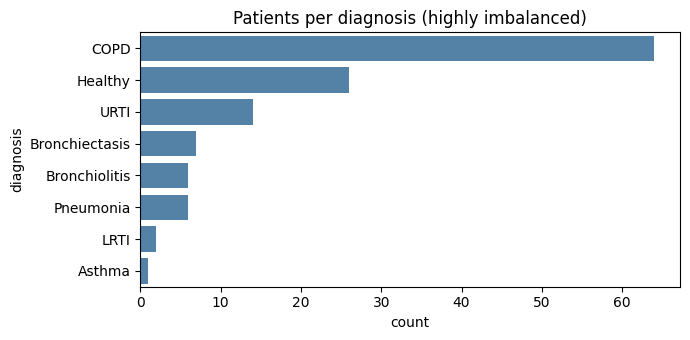

In [ ]:
diag = pd.read_csv(DIAG_CSV, header=None, names=["patient_id", "diagnosis"])
print(diag["diagnosis"].value_counts())

plt.figure(figsize=(7, 3.5))
sns.countplot(data=diag, y="diagnosis", order=diag["diagnosis"].value_counts().index, color="steelblue")
plt.title("Patients per diagnosis (highly imbalanced)")
plt.tight_layout(); plt.show()

## 4. Build the respiratory-cycle table
Each `.txt` annotation line is: `start  end  crackles(0/1)  wheezes(0/1)`.  
Label = `crackle + 2*wheeze`, giving 0 = Normal, 1 = Crackle, 2 = Wheeze, 3 = Both.

Total cycles: 6857 | patients: 126 | recordings: 920
label_name
Normal     3608
Crackle    1861
Wheeze      882
Both        506
Name: count, dtype: int64


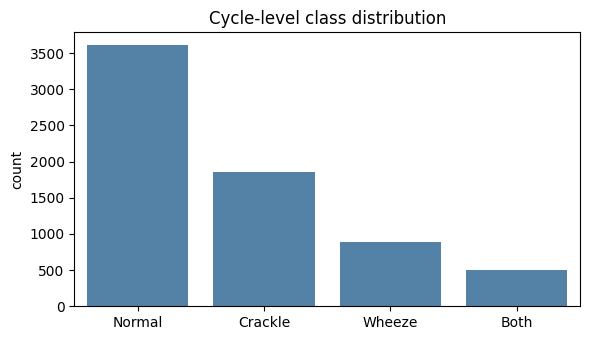

Cycle duration (s):
 count    6857.00
mean        2.71
std         1.16
min         0.50
25%         1.95
50%         2.55
75%         3.37
max        16.16
dtype: float64


In [ ]:
rows = []
for txt in sorted(glob.glob(os.path.join(AUDIO_DIR, "*.txt"))):
    fname = os.path.basename(txt)[:-4]
    wav_path = os.path.join(AUDIO_DIR, fname + ".wav")
    if not os.path.exists(wav_path):
        continue
    pid = int(fname.split("_")[0])
    with open(txt) as f:
        for line in f:
            p = line.strip().split()
            if len(p) < 4:
                continue
            start, end, c, w = float(p[0]), float(p[1]), int(p[2]), int(p[3])
            if end - start < MIN_CYCLE:
                continue
            rows.append(dict(file=fname, patient_id=pid, start=start, end=end,
                             crackle=c, wheeze=w, label=c + 2 * w))

df = pd.DataFrame(rows)
df["label_name"] = df["label"].map(dict(enumerate(CLASS_NAMES)))
print("Total cycles:", len(df), "| patients:", df.patient_id.nunique(), "| recordings:", df.file.nunique())
print(df["label_name"].value_counts())

plt.figure(figsize=(6, 3.5))
sns.countplot(data=df, x="label_name", order=CLASS_NAMES, color="steelblue")
plt.title("Cycle-level class distribution"); plt.xlabel(""); plt.tight_layout(); plt.show()
print("Cycle duration (s):\n", (df.end - df.start).describe().round(2))

## 5. Feature extraction: log-mel spectrograms
Each file is loaded once, cut into cycles, padded or cropped to 5 s, and converted to a log-mel spectrogram.

In [ ]:
def fix_length(y, n=N_SAMPLES):
    if len(y) >= n:
        return y[:n]
    reps = int(np.ceil(n / max(len(y), 1))) + 1
    return np.tile(y, reps)[:n]                      # repeat-pad short cycles

def to_logmel(y):
    y = y / (np.max(np.abs(y)) + 1e-8)               # per-cycle amplitude normalisation
    S = librosa.feature.melspectrogram(y=y, sr=SR, n_fft=N_FFT, hop_length=HOP,
                                       n_mels=N_MELS, fmax=SR // 2)
    return librosa.power_to_db(S, ref=np.max).astype(np.float32)

CACHE = "/content/features.npz"
if os.path.exists(CACHE):
    d = np.load(CACHE)
    X, y_all = d["X"], d["y"]
    print("Loaded cached features:", X.shape)
else:
    feats = np.zeros((len(df), N_MELS, 1 + N_SAMPLES // HOP), dtype=np.float32)
    for fname, g in tqdm(df.groupby("file"), desc="Extracting"):
        sig, _ = librosa.load(os.path.join(AUDIO_DIR, fname + ".wav"), sr=SR, mono=True)
        for idx, r in g.iterrows():
            seg = sig[int(r.start * SR): int(r.end * SR)]
            feats[df.index.get_loc(idx)] = to_logmel(fix_length(seg))
    X, y_all = feats, df["label"].values.astype(np.int32)
    np.savez_compressed(CACHE, X=X, y=y_all)
    print("Features:", X.shape)

Extracting:   0%|          | 0/920 [00:00<?, ?it/s]

Features: (6857, 64, 313)


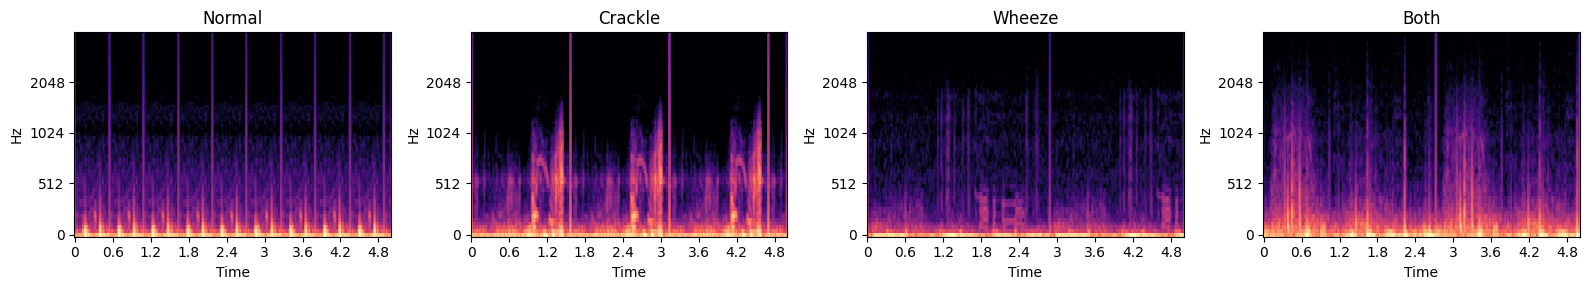

In [ ]:
# Look at one example per class
fig, axes = plt.subplots(1, 4, figsize=(16, 3))
for k, ax in enumerate(axes):
    i = np.where(y_all == k)[0][0]
    librosa.display.specshow(X[i], sr=SR, hop_length=HOP, x_axis="time", y_axis="mel", fmax=SR // 2, ax=ax)
    ax.set_title(CLASS_NAMES[k])
plt.tight_layout(); plt.show()

## 6. Patient-wise train / validation / test split
A random split would put cycles from the same patient in both train and test, which leaks data and inflates results.

In [ ]:
groups = df["patient_id"].values

gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
trainval_idx, test_idx = next(gss.split(X, y_all, groups))

gss2 = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED)
tr_rel, va_rel = next(gss2.split(X[trainval_idx], y_all[trainval_idx], groups[trainval_idx]))
train_idx, val_idx = trainval_idx[tr_rel], trainval_idx[va_rel]

# sanity check: no patient appears in two splits
P = lambda idx: set(groups[idx])
assert not (P(train_idx) & P(val_idx)) and not (P(train_idx) & P(test_idx)) and not (P(val_idx) & P(test_idx))

for name, idx in [("train", train_idx), ("val", val_idx), ("test", test_idx)]:
    counts = np.bincount(y_all[idx], minlength=4)
    print(f"{name:5s} n={len(idx):5d} patients={len(P(idx)):3d} ", dict(zip(CLASS_NAMES, counts)))

# Standardise with TRAIN statistics only
mu, sigma = X[train_idx].mean(), X[train_idx].std()
norm = lambda a: ((a - mu) / (sigma + 1e-8))[..., None].astype(np.float32)
X_train, y_train = norm(X[train_idx]), y_all[train_idx]
X_val,   y_val   = norm(X[val_idx]),   y_all[val_idx]
X_test,  y_test  = norm(X[test_idx]),  y_all[test_idx]

# Class weights to counter imbalance
cw = compute_class_weight("balanced", classes=np.arange(4), y=y_train)
class_weight = {i: float(w) for i, w in enumerate(cw)}
print("Class weights:", {CLASS_NAMES[i]: round(w, 2) for i, w in class_weight.items()})

train n= 4160 patients= 85  {'Normal': np.int64(2386), 'Crackle': np.int64(979), 'Wheeze': np.int64(533), 'Both': np.int64(262)}
val   n=  999 patients= 15  {'Normal': np.int64(424), 'Crackle': np.int64(366), 'Wheeze': np.int64(127), 'Both': np.int64(82)}
test  n= 1698 patients= 26  {'Normal': np.int64(798), 'Crackle': np.int64(516), 'Wheeze': np.int64(222), 'Both': np.int64(162)}
Class weights: {'Normal': 0.44, 'Crackle': 1.06, 'Wheeze': 1.95, 'Both': 3.97}


## 7. tf.data pipeline with SpecAugment (training only)

In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

def spec_augment(x, y, max_f=8, max_t=40):
    # x: (n_mels, T, 1) already standardised, so masked regions become the mean (0)
    n_mels, T = tf.shape(x)[0], tf.shape(x)[1]
    f  = tf.random.uniform([], 0, max_f + 1, dtype=tf.int32)
    f0 = tf.random.uniform([], 0, n_mels - f + 1, dtype=tf.int32)
    fmask = tf.concat([tf.ones([f0]), tf.zeros([f]), tf.ones([n_mels - f0 - f])], 0)
    t  = tf.random.uniform([], 0, max_t + 1, dtype=tf.int32)
    t0 = tf.random.uniform([], 0, T - t + 1, dtype=tf.int32)
    tmask = tf.concat([tf.ones([t0]), tf.zeros([t]), tf.ones([T - t0 - t])], 0)
    x = x * fmask[:, None, None] * tmask[None, :, None]
    x = x + tf.random.normal(tf.shape(x), stddev=0.05)       # light noise
    return x, y

def make_ds(X_, y_, training):
    ds = tf.data.Dataset.from_tensor_slices((X_, y_))
    if training:
        ds = ds.shuffle(len(X_), seed=SEED, reshuffle_each_iteration=True)
        ds = ds.map(spec_augment, num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH).prefetch(AUTOTUNE)

train_ds = make_ds(X_train, y_train, True)
val_ds   = make_ds(X_val,   y_val,   False)
test_ds  = make_ds(X_test,  y_test,  False)

## 8. CNN model

In [ ]:
def build_model(input_shape, n_classes=4):
    inp = keras.Input(shape=input_shape)
    x = inp
    for filters in [32, 64, 128, 128]:
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.ReLU()(x)
        x = layers.MaxPooling2D(2)(x)
        x = layers.Dropout(0.25)(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(64, activation="relu")(x)
    x = layers.Dropout(0.4)(x)
    out = layers.Dense(n_classes, activation="softmax")(x)
    return keras.Model(inp, out, name="lung_sound_cnn")

model = build_model(X_train.shape[1:])
model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
model.summary()

Model: "lung_sound_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 64, 313, 1)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 313, 32)    │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 313, 32)    │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 64, 313, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 156, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32, 156, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 156, 64)    │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 156, 64)    │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 32, 156, 64)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 78, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16, 78, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 78, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 78, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 16, 78, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 39, 128)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 8, 39, 128)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 8, 39, 128)     │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 8, 39, 128)     │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 8, 39, 128)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 4, 19, 128)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 4, 19, 128)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 249,828 (975.89 KB)

 Trainable params: 249,124 (973.14 KB)

 Non-trainable params: 704 (2.75 KB)

## 9. Train

In [ ]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=12, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=5, min_lr=1e-5, verbose=1),
    keras.callbacks.ModelCheckpoint("best_model.keras", monitor="val_loss", save_best_only=True),
]
history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS,
                    class_weight=class_weight, callbacks=callbacks)

Epoch 1/60
130/130 ━━━━━━━━━━━━━━━━━━━━ 24s 50ms/step - accuracy: 0.3361 - loss: 1.3857 - val_accuracy: 0.3664 - val_loss: 1.3866 - learning_rate: 0.0010
Epoch 2/60
130/130 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step - accuracy: 0.3481 - loss: 1.3309 - val_accuracy: 0.3944 - val_loss: 1.2881 - learning_rate: 0.0010
Epoch 3/60
130/130 ━━━━━━━━━━━━━━━━━━━━ 4s 32ms/step - accuracy: 0.3755 - loss: 1.3008 - val_accuracy: 0.3654 - val_loss: 1.3326 - learning_rate: 0.0010
Epoch 4/60
130/130 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step - accuracy: 0.3913 - loss: 1.2784 - val_accuracy: 0.3794 - val_loss: 1.2324 - learning_rate: 0.0010
Epoch 5/60
130/130 ━━━━━━━━━━━━━━━━━━━━ 4s 32ms/step - accuracy: 0.4007 - loss: 1.2548 - val_accuracy: 0.2503 - val_loss: 1.4932 - learning_rate: 0.0010
Epoch 6/60
130/130 ━━━━━━━━━━━━━━━━━━━━ 5s 32ms/step - accuracy: 0.4197 - loss: 1.2363 - val_accuracy: 0.3824 - val_loss: 1.2874 - learning_rate: 0.0010
Epoch 7/60
130/130 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step - accuracy: 0.4151 - loss: 1

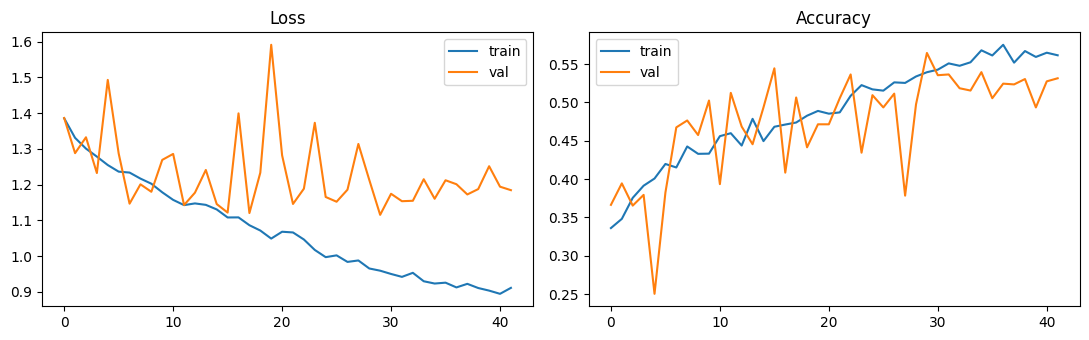

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(history.history["loss"], label="train"); ax[0].plot(history.history["val_loss"], label="val")
ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(history.history["accuracy"], label="train"); ax[1].plot(history.history["val_accuracy"], label="val")
ax[1].set_title("Accuracy"); ax[1].legend()
plt.tight_layout(); plt.show()

## 10. Evaluate on the held-out test patients
Because the data is imbalanced, look at **macro-F1, per-class recall and the confusion matrix**, not accuracy alone. The **ICBHI score** is the standard metric for this dataset: (Specificity + Sensitivity) / 2.

              precision    recall  f1-score   support

      Normal      0.565     0.368     0.446       798
     Crackle      0.387     0.643     0.484       516
      Wheeze      0.464     0.234     0.311       222
        Both      0.225     0.290     0.253       162

    accuracy                          0.427      1698
   macro avg      0.410     0.384     0.374      1698
weighted avg      0.466     0.427     0.422      1698

Accuracy          : 0.427
Balanced accuracy : 0.384
Macro F1          : 0.3736
ICBHI score       : 0.4237  (Sp=0.368, Se=0.479)


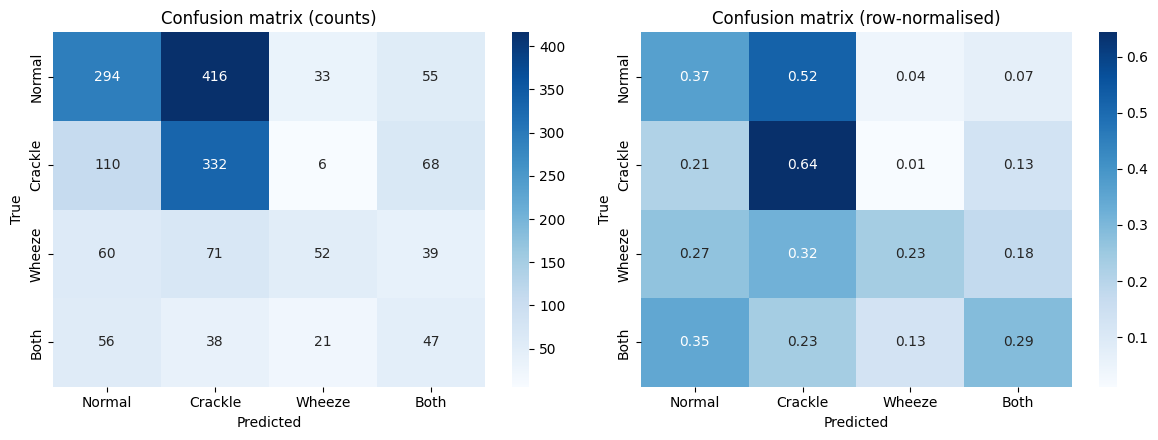

In [ ]:
y_prob = model.predict(test_ds, verbose=0)
y_pred = y_prob.argmax(1)

print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=3, zero_division=0))
print("Accuracy          :", round((y_pred == y_test).mean(), 4))
print("Balanced accuracy :", round(balanced_accuracy_score(y_test, y_pred), 4))
print("Macro F1          :", round(f1_score(y_test, y_pred, average="macro"), 4))

cm = confusion_matrix(y_test, y_pred, labels=range(4))
sp = cm[0, 0] / cm[0].sum()                              # specificity (Normal)
se = np.trace(cm[1:, 1:]) / cm[1:].sum()                 # sensitivity (abnormal classes)
print(f"ICBHI score       : {(sp + se) / 2:.4f}  (Sp={sp:.3f}, Se={se:.3f})")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax[0])
ax[0].set_title("Confusion matrix (counts)"); ax[0].set_xlabel("Predicted"); ax[0].set_ylabel("True")
sns.heatmap(cm / cm.sum(1, keepdims=True), annot=True, fmt=".2f", cmap="Blues",
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax[1])
ax[1].set_title("Confusion matrix (row-normalised)"); ax[1].set_xlabel("Predicted"); ax[1].set_ylabel("True")
plt.tight_layout(); plt.show()

## 11. Predict on a single recording
Uses the cycle annotations to classify each breath cycle in a chosen file.

In [ ]:
def predict_recording(fname):
    sig, _ = librosa.load(os.path.join(AUDIO_DIR, fname + ".wav"), sr=SR, mono=True)
    cyc = df[df.file == fname]
    batch = np.stack([to_logmel(fix_length(sig[int(r.start*SR):int(r.end*SR)])) for _, r in cyc.iterrows()])
    probs = model.predict(norm(batch), verbose=0)
    out = cyc[["start", "end", "label_name"]].copy().rename(columns={"label_name": "true"})
    out["predicted"] = [CLASS_NAMES[i] for i in probs.argmax(1)]
    out["confidence"] = probs.max(1).round(3)
    return out

example = df[df.index.isin(test_idx)].file.iloc[0]
print("Recording:", example)
predict_recording(example)

Recording: 101_1b1_Al_sc_Meditron


,start,end,true,predicted,confidence
0,0.036,0.579,Normal,Normal,0.618
1,0.579,2.450,Normal,Normal,0.623
2,2.450,3.893,Normal,Normal,0.569
3,3.893,5.793,Normal,Normal,0.527
4,5.793,7.521,Normal,Normal,0.549
5,7.521,9.279,Normal,Normal,0.591
6,9.279,11.150,Normal,Normal,0.657
7,11.150,13.036,Normal,Normal,0.488
8,13.036,14.721,Normal,Normal,0.624
9,14.721,16.707,Normal,Normal,0.691
